# Segmentación de Pacientes Mediante Técnicas de Clustering Basadas en Indicadores Clínicos Cardiovasculares

**Universidad de la Costa – CUC**  
**Facultad de Ingeniería — Departamento de Ciencias de la Computación y Electrónica**  
**Asignatura:** Minería de Datos (Tercer Corte — Integración y Despliegue en Streamlit)  
**Tipo de proyecto:** Clustering (aprendizaje no supervisado)  
**Dataset:** Heart Disease UCI (Cleveland Clinic Foundation — [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Heart+Disease) / Kaggle)  
**Integrantes:** Fernando Barbosa, Daliany Rojas León, Kevin Muñoz, Jose Díaz

## 1. Descripción del Problema, Objetivo y Variables

Las enfermedades cardiovasculares constituyen la principal causa de mortalidad a nivel mundial. En el análisis exploratorio de registros clínicos, las técnicas de **aprendizaje no supervisado (clustering)** permiten descubrir subgrupos de pacientes con perfiles fisiológicos y clínicos diferenciados sin depender de una etiqueta diagnóstica previa.

**Objetivo:** Revisar el rendimiento obtenido en el segundo corte, optimizar el *pipeline* de preprocesamiento y modelado no supervisado sobre el conjunto de datos **Heart Disease UCI**, serializar el flujo completo con `joblib` y desplegar una aplicación web reproducible en **Streamlit Community Cloud** con validación de entradas y pruebas de consistencia frente al notebook.

> **Aviso académico:** Este desarrollo corresponde a un prototipo académico exploratorio y **no sustituye una valoración ni un diagnóstico médico profesional**.

| # | Variable | Descripción | Tipo en el Pipeline |
|---:|---|---|---|
| 1 | `age` | Edad del paciente (años) | Numérica continua (`StandardScaler`) |
| 2 | `trestbps` | Presión arterial en reposo (mm Hg) | Numérica continua (`StandardScaler`) |
| 3 | `chol` | Colesterol sérico (mg/dl) | Numérica continua (`StandardScaler`) |
| 4 | `thalach` | Frecuencia cardíaca máxima alcanzada (lpm) | Numérica continua (`StandardScaler`) |
| 5 | `oldpeak` | Depresión del segmento ST inducida por ejercicio | Numérica continua (`StandardScaler`) |
| 6 | `ca` | Número de vasos principales coloreados por fluoroscopía (0–4) | Numérica discreta (`StandardScaler`) |
| 7 | `sex` | Sexo biológico (0 = Mujer, 1 = Hombre) | Binaria (`passthrough`) |
| 8 | `fbs` | Glucosa en ayunas > 120 mg/dl (0 = No, 1 = Sí) | Binaria (`passthrough`) |
| 9 | `exang` | Angina inducida por ejercicio (0 = No, 1 = Sí) | Binaria (`passthrough`) |
| 10 | `cp` | Tipo de dolor torácico (0 = Angina típica, 1 = Atípica, 2 = No anginoso, 3 = Asintomático) | Categórica nominal (`OneHotEncoder`) |
| 11 | `restecg` | Resultados del electrocardiograma en reposo (0–2) | Categórica nominal (`OneHotEncoder`) |
| 12 | `slope` | Pendiente del segmento ST en ejercicio máximo (0–2) | Categórica nominal (`OneHotEncoder`) |
| 13 | `thal` | Resultado de talasemia (0–3) | Categórica nominal (`OneHotEncoder`) |
| — | `target` | Referencia diagnóstica del dataset original (excluida del clustering) | Solo contraste exploratorio |

## 2. Carga de Librerías y Conjunto de Datos

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120

Path('figures').mkdir(exist_ok=True)
Path('models').mkdir(exist_ok=True)

data_path = Path('data/heart.csv')
if not data_path.exists():
    data_path = Path('repositorio_github/data/heart.csv')

df = pd.read_csv(data_path)
print(f'Dimensiones iniciales del dataset: {df.shape[0]} registros x {df.shape[1]} columnas')
df.head()

Dimensiones iniciales del dataset: 303 registros x 14 columnas


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## 3. Diagnóstico de Calidad de Datos y Análisis Exploratorio (EDA)

In [2]:
print('Valores nulos totales:', int(df.isnull().sum().sum()))
duplicados = int(df.duplicated().sum())
print('Registros duplicados detectados:', duplicados)

df_clean = df.drop_duplicates().reset_index(drop=True)
print(f'Registros únicos tras limpieza: {len(df_clean)} ({len(df_clean)} filas x {df_clean.shape[1]} columnas)')

# Separar variables predictoras (13) de la variable de referencia diagnóstica (target)
FEATURES = [
    'age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca',
    'sex', 'fbs', 'exang', 'cp', 'restecg', 'slope', 'thal'
]
NUM_COLS = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
BIN_COLS = ['sex', 'fbs', 'exang']
NOM_COLS = ['cp', 'restecg', 'slope', 'thal']

X = df_clean[FEATURES].copy()
target_ref = df_clean['target'].copy()

df_clean[FEATURES].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2)

Valores nulos totales: 0
Registros duplicados detectados: 1
Registros únicos tras limpieza: 302 (302 filas x 14 columnas)


,count,mean,std,min,50%,max
age,302.0,54.42,9.05,29.0,55.5,77.0
trestbps,302.0,131.60,17.56,94.0,130.0,200.0
chol,302.0,246.50,51.75,126.0,240.5,564.0
thalach,302.0,149.57,22.90,71.0,152.5,202.0
oldpeak,302.0,1.04,1.16,0.0,0.8,6.2
ca,302.0,0.72,1.01,0.0,0.0,4.0
sex,302.0,0.68,0.47,0.0,1.0,1.0
fbs,302.0,0.15,0.36,0.0,0.0,1.0
exang,302.0,0.33,0.47,0.0,0.0,1.0
cp,302.0,0.96,1.03,0.0,1.0,3.0


In [3]:
# Análisis de valores atípicos mediante rango intercuartílico (IQR) en variables continuas
vars_continuas = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
iqr_rows = []
for col in vars_continuas:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_out = int(((X[col] < low) | (X[col] > high)).sum())
    iqr_rows.append({'Variable': col, 'Q1': q1, 'Q3': q3, 'Limite_Inf': round(low, 2), 'Limite_Sup': round(high, 2), 'Outliers_IQR': n_out})

iqr_df = pd.DataFrame(iqr_rows)
print('Nota: Los valores atípicos se conservan por ser clínicamente plausibles en población cardiovascular.')
iqr_df

Nota: Los valores atípicos se conservan por ser clínicamente plausibles en población cardiovascular.


,Variable,Q1,Q3,Limite_Inf,Limite_Sup,Outliers_IQR
0,age,48.00,61.00,28.50,80.50,0
1,trestbps,120.00,140.00,90.00,170.00,9
2,chol,211.00,274.75,115.38,370.38,5
3,thalach,133.25,166.00,84.12,215.12,1
4,oldpeak,0.00,1.60,-2.40,4.00,5


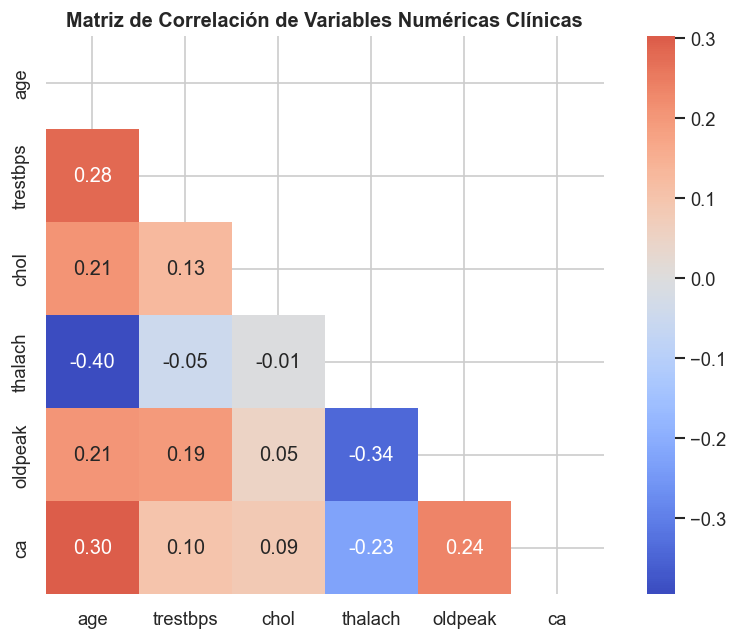

In [4]:
# Correlación entre variables numéricas continuas y discretas
fig, ax = plt.subplots(figsize=(7.5, 5.5))
corr = X[NUM_COLS].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=ax)
ax.set_title('Matriz de Correlación de Variables Numéricas Clínicas', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/correlacion_eda.png', dpi=300, bbox_inches='tight')
plt.show()

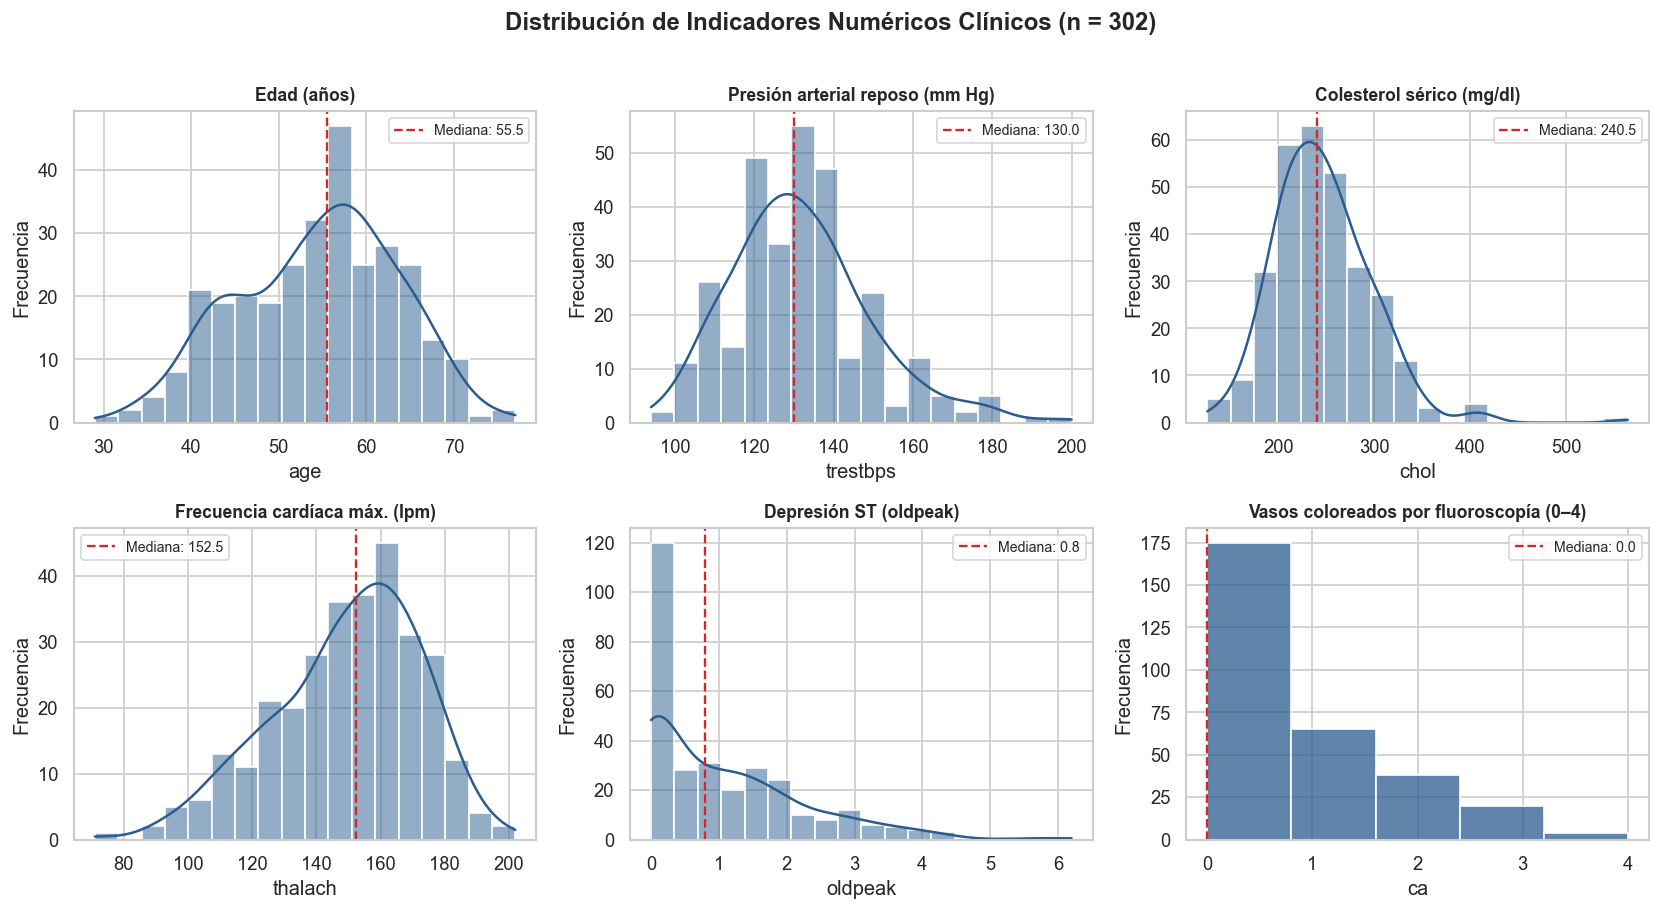

In [5]:
# Visualización EDA 1: Distribución de variables numéricas clínicas (n = 302)
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
axes = axes.ravel()
titles_num = {
    'age': 'Edad (años)',
    'trestbps': 'Presión arterial reposo (mm Hg)',
    'chol': 'Colesterol sérico (mg/dl)',
    'thalach': 'Frecuencia cardíaca máx. (lpm)',
    'oldpeak': 'Depresión ST (oldpeak)',
    'ca': 'Vasos coloreados por fluoroscopía (0–4)'
}
for idx, col in enumerate(NUM_COLS):
    sns.histplot(X[col], kde=(col != 'ca'), bins=18 if col != 'ca' else 5, color='#2b5c8f', ax=axes[idx])
    axes[idx].axvline(X[col].median(), color='#d62728', linestyle='--', linewidth=1.4, label=f'Mediana: {X[col].median():.1f}')
    axes[idx].set_title(titles_num[col], fontweight='bold', fontsize=10.5)
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Frecuencia')
    axes[idx].legend(fontsize=8.5)

plt.suptitle('Distribución de Indicadores Numéricos Clínicos (n = 302)', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/eda_distribuciones_clinicas.png', dpi=300, bbox_inches='tight')
plt.show()

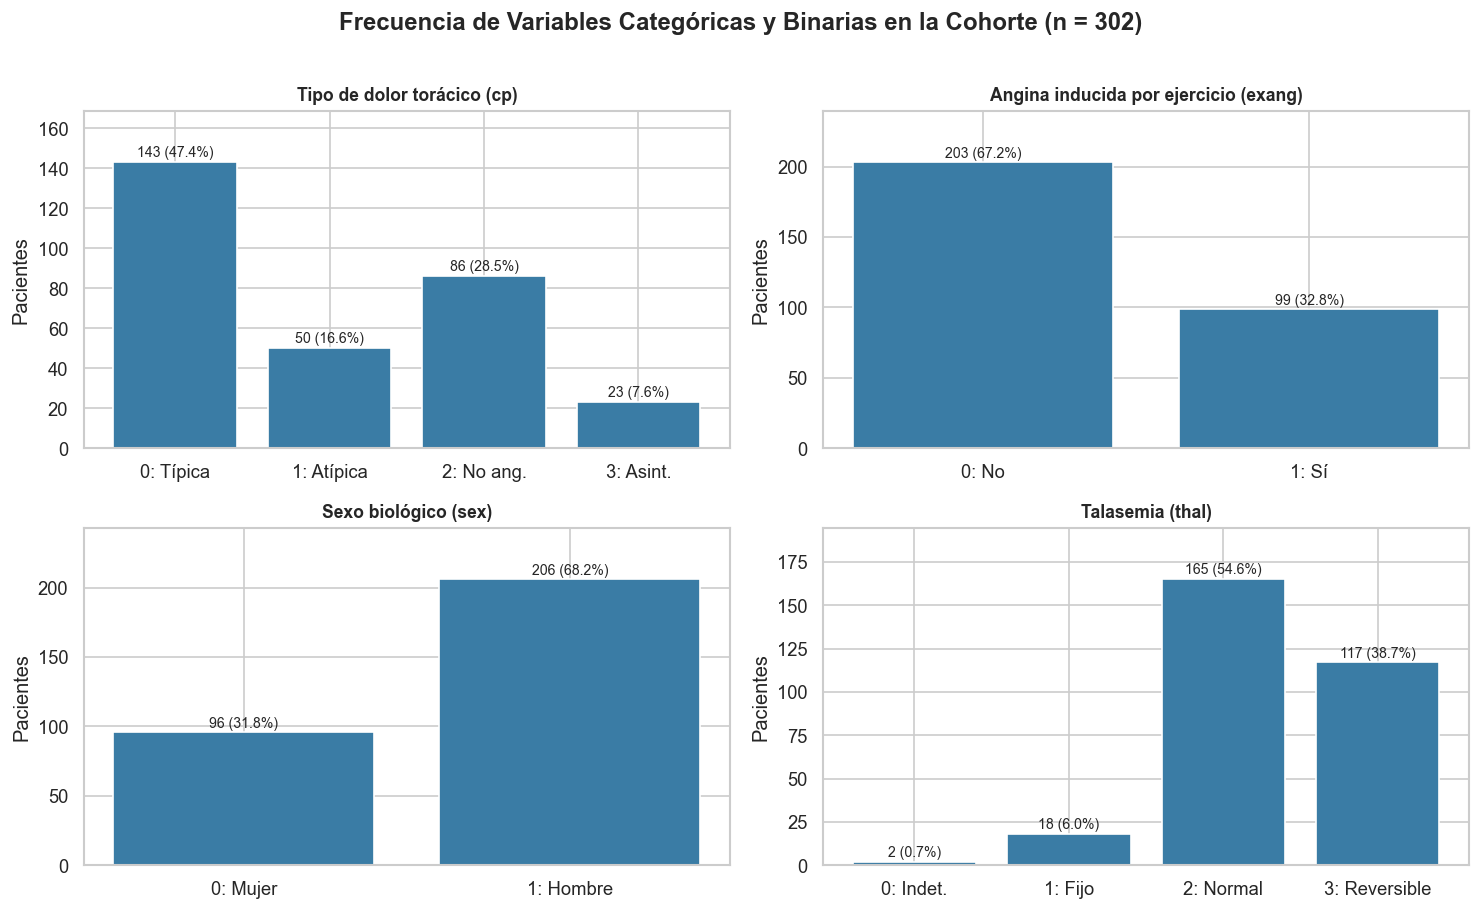

In [6]:
# Visualización EDA 2: Distribución de variables categóricas y binarias clave
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.5))
cat_specs = [
    ('cp', 'Tipo de dolor torácico (cp)', {0: '0: Típica', 1: '1: Atípica', 2: '2: No ang.', 3: '3: Asint.'}),
    ('exang', 'Angina inducida por ejercicio (exang)', {0: '0: No', 1: '1: Sí'}),
    ('sex', 'Sexo biológico (sex)', {0: '0: Mujer', 1: '1: Hombre'}),
    ('thal', 'Talasemia (thal)', {0: '0: Indet.', 1: '1: Fijo', 2: '2: Normal', 3: '3: Reversible'}),
]
for ax, (col, title, mapping) in zip(axes.ravel(), cat_specs):
    vc = X[col].value_counts().sort_index()
    labels = [mapping.get(int(k), str(k)) for k in vc.index]
    bars = ax.bar(labels, vc.values, color='#3a7ca5', edgecolor='white')
    ax.set_title(title, fontweight='bold', fontsize=10.5)
    ax.set_ylabel('Pacientes')
    ax.set_ylim(0, max(vc.values) * 1.18)
    for b, val in zip(bars, vc.values):
        ax.text(b.get_x() + b.get_width()/2, val + 3, f'{val} ({val/len(X)*100:.1f}%)', ha='center', fontsize=8.5)

plt.suptitle('Frecuencia de Variables Categóricas y Binarias en la Cohorte (n = 302)', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/eda_categoricas_clinicas.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Revisión Técnica del Preprocesamiento y Comparación de Enfoques (Métrica < 0.70)

En el **segundo avance** se aplicó `StandardScaler` directamente sobre las 13 variables tratadas como numéricas ordinales, obteniendo con K-means ($k=2$) un coeficiente de silueta de **0.1681** e índice de Davies-Bouldin de **2.1900**. Dado que el coeficiente de silueta es inferior a 0.70, se realizó una revisión técnica sistemática siguiendo dos criterios:
1. **Corregir la asunción ordinal:** las variables `cp`, `restecg`, `slope` y `thal` representan categorías nominales médicas, por lo que codificarlas mediante `OneHotEncoder` dentro de un `ColumnTransformer` evita imponer distancias lineales artificiales entre categorías.
2. **Contrastes sin manipulación artificial:** se comparó el esquema base del Corte 2 frente al esquema mixto (`StandardScaler` + `OneHotEncoder`), frente a `RobustScaler` + `OneHotEncoder` (por la presencia de outliers en `trestbps`, `chol`, `oldpeak` y `thalach`) y frente a algoritmos alternativos (`AgglomerativeClustering` y `GaussianMixture`).

In [7]:
# Comparación controlada de enfoques para k=2
results_comp = []

# 1) Baseline Corte 2: StandardScaler sobre las 13 columnas crudas + KMeans
X_c2 = StandardScaler().fit_transform(X)
km_c2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_c2)
results_comp.append({
    'Configuracion': 'Corte 2: StandardScaler (13 raw) + KMeans',
    'Dimensiones': X_c2.shape[1],
    'Silueta': round(silhouette_score(X_c2, km_c2.labels_), 4),
    'Davies_Bouldin': round(davies_bouldin_score(X_c2, km_c2.labels_), 4),
    'Calinski_Harabasz': round(calinski_harabasz_score(X_c2, km_c2.labels_), 2)
})

# 2) Corte 3 propuesto: ColumnTransformer (StandardScaler num + passthrough bin + OneHot nominal) + KMeans
prep_std_ohe = ColumnTransformer([
    ('num', StandardScaler(), NUM_COLS),
    ('bin', 'passthrough', BIN_COLS),
    ('nom', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), NOM_COLS)
])
X_std_ohe = prep_std_ohe.fit_transform(X)
km_std_ohe = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_std_ohe)
results_comp.append({
    'Configuracion': 'Corte 3: StandardScaler + OneHotEncoder + KMeans',
    'Dimensiones': X_std_ohe.shape[1],
    'Silueta': round(silhouette_score(X_std_ohe, km_std_ohe.labels_), 4),
    'Davies_Bouldin': round(davies_bouldin_score(X_std_ohe, km_std_ohe.labels_), 4),
    'Calinski_Harabasz': round(calinski_harabasz_score(X_std_ohe, km_std_ohe.labels_), 2)
})

# 3) Alternativa con RobustScaler + OneHotEncoder + KMeans
prep_rob_ohe = ColumnTransformer([
    ('num', RobustScaler(), NUM_COLS),
    ('bin', 'passthrough', BIN_COLS),
    ('nom', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), NOM_COLS)
])
X_rob_ohe = prep_rob_ohe.fit_transform(X)
km_rob_ohe = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_rob_ohe)
results_comp.append({
    'Configuracion': 'Alternativa: RobustScaler + OneHotEncoder + KMeans',
    'Dimensiones': X_rob_ohe.shape[1],
    'Silueta': round(silhouette_score(X_rob_ohe, km_rob_ohe.labels_), 4),
    'Davies_Bouldin': round(davies_bouldin_score(X_rob_ohe, km_rob_ohe.labels_), 4),
    'Calinski_Harabasz': round(calinski_harabasz_score(X_rob_ohe, km_rob_ohe.labels_), 2)
})

# 4) AgglomerativeClustering (Ward) sobre espacio Std+OHE
agg = AgglomerativeClustering(n_clusters=2, linkage='ward').fit(X_std_ohe)
results_comp.append({
    'Configuracion': 'Alternativa: StandardScaler + OneHotEncoder + Ward',
    'Dimensiones': X_std_ohe.shape[1],
    'Silueta': round(silhouette_score(X_std_ohe, agg.labels_), 4),
    'Davies_Bouldin': round(davies_bouldin_score(X_std_ohe, agg.labels_), 4),
    'Calinski_Harabasz': round(calinski_harabasz_score(X_std_ohe, agg.labels_), 2)
})

# 5) GaussianMixture sobre espacio Std+OHE
gmm = GaussianMixture(n_components=2, random_state=42).fit_predict(X_std_ohe)
results_comp.append({
    'Configuracion': 'Alternativa: StandardScaler + OneHotEncoder + GMM',
    'Dimensiones': X_std_ohe.shape[1],
    'Silueta': round(silhouette_score(X_std_ohe, gmm), 4),
    'Davies_Bouldin': round(davies_bouldin_score(X_std_ohe, gmm), 4),
    'Calinski_Harabasz': round(calinski_harabasz_score(X_std_ohe, gmm), 2)
})

comp_df = pd.DataFrame(results_comp)
comp_df

,Configuracion,Dimensiones,Silueta,Davies_Bouldin,Calinski_Harabasz
0,Corte 2: StandardScaler (13 raw) + KMeans,13,0.1681,2.1900,54.99
1,Corte 3: StandardScaler + OneHotEncoder + KMeans,23,0.1722,2.0650,66.61
2,Alternativa: RobustScaler + OneHotEncoder + KM...,23,0.1727,2.1197,59.55
3,Alternativa: StandardScaler + OneHotEncoder + ...,23,0.1019,2.2109,45.29
4,Alternativa: StandardScaler + OneHotEncoder + GMM,23,0.0791,3.7787,11.71


**Resultado de la revisión técnica:**
- El esquema **Corte 3 (`StandardScaler` + `OneHotEncoder` + `KMeans`)** corrige el tratamiento ordinal indebido del Corte 2 y mejora simultáneamente las tres métricas de validación interna respecto al Corte 2: la **silueta** pasa de `0.1681` a `0.1722`, el índice **Davies-Bouldin** mejora de `2.1900` a `2.0650` (menor es mejor) y **Calinski-Harabasz** sube de `54.99` a `66.61`.
- Frente a `RobustScaler + OHE` (`silueta = 0.1727`, pero peor `DB = 2.1197` y `CH = 59.55`), agrupamiento jerárquico `Ward` (`silueta = 0.1019`, `DB = 2.2109`, `CH = 45.29`) y `GMM` (`silueta = 0.0791`, `DB = 3.7787`, `CH = 11.71`), `StandardScaler + OneHotEncoder + KMeans` ofrece el mejor equilibrio entre cohesión, separación y simplicidad de inferencia en un `Pipeline` único.
- El hecho de que ninguna técnica alcance `0.70` confirma que los datos clínicos cardiovasculares forman un continuo fisiológico con solapamiento natural, no clústeres geométricamente aislados.

### 4.1 Auditoría Técnica del Pipeline (Alerta de Métrica < 0.70)

Siguiendo la **Ficha técnica de revisión de calidad del modelado** para métricas inferiores a `0.70`, se ejecutó una verificación programática sobre las ocho dimensiones críticas adaptadas al aprendizaje no supervisado:

1. **Tratamiento de datos:** `0` valores nulos, `1` duplicado eliminado (`303 -> 302`), conservación justificada de atípicos clínicamente plausibles y corrección de nominales con `OneHotEncoder`.
2. **Fuga de información:** exclusión estricta de `target` en `FEATURES`, entrenamiento y serialización.
3. **Separación entrenamiento/prueba y validación cruzada (estabilidad):** evaluación por 5 particiones (*5-fold* fuera de muestra, ajustando el `Pipeline` en el 80% y prediciendo en el 20% restante) más estabilidad multi-semilla.
4. **Desbalance:** verificación del tamaño relativo entre clústeres y composición demográfica (`sex`).
5. **Colinealidad:** revisión de la correlación máxima por pares y Factor de Inflación de la Varianza (VIF) sobre `NUM_COLS`.
6. **Sobreajuste e hiperparámetros:** contraste de convergencia de `n_init` (`10`, `20`, `50`) y justificación de `k=2` frente a `k=3..8`.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import KFold

# 1. Verificación de fuga de información
assert 'target' not in FEATURES, 'Error: fuga de información detectada (target en FEATURES)'

# 2. Colinealidad: correlación máxima y VIF en variables numéricas
corr_abs = X[NUM_COLS].corr().abs()
np.fill_diagonal(corr_abs.values, 0.0)
max_corr = float(corr_abs.max().max())

vif_rows = []
for col in NUM_COLS:
    otros = [c for c in NUM_COLS if c != col]
    r2 = LinearRegression().fit(X[otros], X[col]).score(X[otros], X[col])
    vif = 1.0 / (1.0 - r2) if r2 < 0.9999 else np.inf
    vif_rows.append({'Variable': col, 'VIF': round(float(vif), 3)})
vif_df = pd.DataFrame(vif_rows)

# 3. Estabilidad por validación cruzada (5-fold fuera de muestra)
pipe_base = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', StandardScaler(), NUM_COLS),
        ('bin', 'passthrough', BIN_COLS),
        ('nom', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), NOM_COLS)
    ])),
    ('kmeans', KMeans(n_clusters=2, random_state=42, n_init=10))
])
labels_full = pipe_base.fit_predict(X)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
sil_train_folds, sil_test_folds, ari_test_folds = [], [], []
for train_idx, test_idx in kf.split(X):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    p_fold = Pipeline([
        ('preprocessor', ColumnTransformer([
            ('num', StandardScaler(), NUM_COLS),
            ('bin', 'passthrough', BIN_COLS),
            ('nom', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), NOM_COLS)
        ])),
        ('kmeans', KMeans(n_clusters=2, random_state=42, n_init=10))
    ])
    tr_labels = p_fold.fit_predict(X_tr)
    te_labels = p_fold.predict(X_te)
    sil_train_folds.append(silhouette_score(p_fold.named_steps['preprocessor'].transform(X_tr), tr_labels))
    sil_test_folds.append(silhouette_score(p_fold.named_steps['preprocessor'].transform(X_te), te_labels))
    ari_test_folds.append(adjusted_rand_score(labels_full[test_idx], te_labels))

# 4. Estabilidad de hiperparámetros (semillas y n_init)
ari_seeds = []
for seed in [0, 7, 21, 99]:
    lbl_s = KMeans(n_clusters=2, random_state=seed, n_init=10).fit_predict(X_std_ohe)
    ari_seeds.append(adjusted_rand_score(labels_full, lbl_s))

inercia_ninit = {
    ni: round(float(KMeans(n_clusters=2, random_state=42, n_init=ni).fit(X_std_ohe).inertia_), 2)
    for ni in [10, 20, 50]
}

# 5. Balance de clústeres
sz = pd.Series(labels_full).value_counts().sort_index()
ratio_balance = round(float(sz.max() / sz.min()), 2)

print('=== AUDITORÍA DE CALIDAD DEL PIPELINE (FICHA TÉCNICA < 0.70) ===')
print(f'1. Fuga de información: Ninguna (target excluido; {len(FEATURES)} variables de entrada)')
print(f'2. Colinealidad: |r| máx. = {max_corr:.2f} | VIF máx. = {vif_df["VIF"].max():.3f} (todos < 5)')
print(f'3. Validación 5-fold (train): Silueta = {np.mean(sil_train_folds):.4f} ± {np.std(sil_train_folds):.4f}')
print(f'   Validación 5-fold (test):  Silueta = {np.mean(sil_test_folds):.4f} ± {np.std(sil_test_folds):.4f} | ARI vs full = {np.mean(ari_test_folds):.4f}')
print(f'4. Estabilidad multi-semilla (ARI): min={min(ari_seeds):.4f}, media={np.mean(ari_seeds):.4f}')
print(f'5. Convergencia de hiperparámetro n_init (inercia): {inercia_ninit}')
print(f'6. Desbalance de clústeres: {sz.to_dict()} (razón {ratio_balance}:1, equilibrado)')
vif_df

=== AUDITORÍA DE CALIDAD DEL PIPELINE (FICHA TÉCNICA < 0.70) ===
1. Fuga de información: Ninguna (target excluido; 13 variables de entrada)
2. Colinealidad: |r| máx. = 0.40 | VIF máx. = 1.407 (todos < 5)
3. Validación 5-fold (train): Silueta = 0.1705 ± 0.0051
   Validación 5-fold (test):  Silueta = 0.1687 ± 0.0215 | ARI vs full = 0.9733
4. Estabilidad multi-semilla (ARI): min=1.0000, media=1.0000
5. Convergencia de hiperparámetro n_init (inercia): {10: 2186.73, 20: 2186.73, 50: 2186.73}
6. Desbalance de clústeres: {0: 137, 1: 165} (razón 1.2:1, equilibrado)


,Variable,VIF
0,age,1.407
1,trestbps,1.131
2,chol,1.059
3,thalach,1.330
4,oldpeak,1.206
5,ca,1.148


## 5. Selección del Número Óptimo de Clústeres ($k = 2$ a $8$)

In [9]:
ks = list(range(2, 9))
metricas_k = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_std_ohe)
    metricas_k.append({
        'k': k,
        'Inercia': round(km.inertia_, 2),
        'Silueta': round(silhouette_score(X_std_ohe, labels_k), 4),
        'Davies_Bouldin': round(davies_bouldin_score(X_std_ohe, labels_k), 4),
        'Calinski_Harabasz': round(calinski_harabasz_score(X_std_ohe, labels_k), 2)
    })

df_k = pd.DataFrame(metricas_k)
df_k

,k,Inercia,Silueta,Davies_Bouldin,Calinski_Harabasz
0,2,2186.73,0.1722,2.0650,66.61
1,3,2007.39,0.1180,2.3125,49.51
2,4,1877.15,0.1174,2.2113,42.07
3,5,1772.17,0.1260,2.0097,37.71
4,6,1702.21,0.1230,2.0031,33.74
5,7,1637.04,0.1055,2.0730,31.09
6,8,1591.51,0.0913,2.2099,28.52


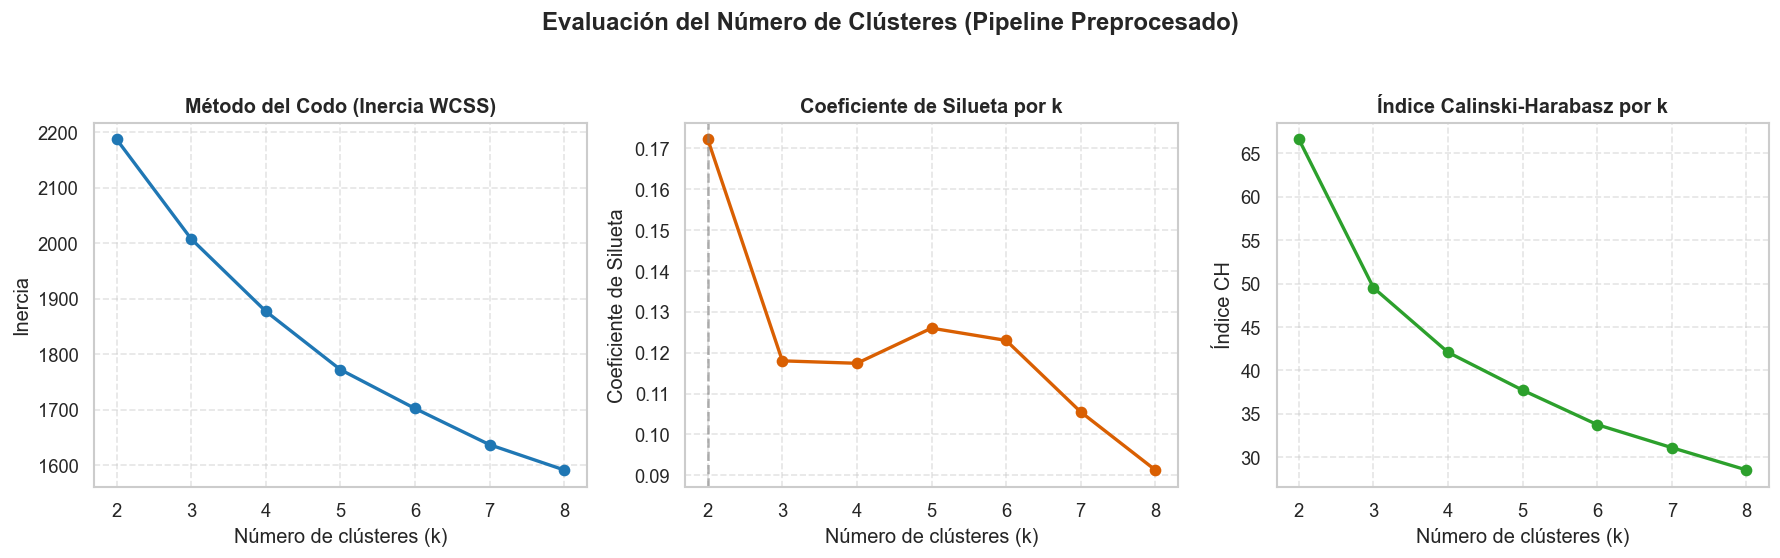

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(df_k['k'], df_k['Inercia'], marker='o', linewidth=2, color='#1f77b4')
axes[0].set_title('Método del Codo (Inercia WCSS)', fontweight='bold')
axes[0].set_xlabel('Número de clústeres (k)')
axes[0].set_ylabel('Inercia')
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(df_k['k'], df_k['Silueta'], marker='o', linewidth=2, color='#d95f02')
axes[1].axvline(2, color='gray', linestyle='--', alpha=0.6)
axes[1].set_title('Coeficiente de Silueta por k', fontweight='bold')
axes[1].set_xlabel('Número de clústeres (k)')
axes[1].set_ylabel('Coeficiente de Silueta')
axes[1].grid(True, linestyle='--', alpha=0.5)

axes[2].plot(df_k['k'], df_k['Calinski_Harabasz'], marker='o', linewidth=2, color='#2ca02c')
axes[2].set_title('Índice Calinski-Harabasz por k', fontweight='bold')
axes[2].set_xlabel('Número de clústeres (k)')
axes[2].set_ylabel('Índice CH')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Evaluación del Número de Clústeres (Pipeline Preprocesado)', fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('figures/seleccion_k.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Pipeline Final (K-means, $k=2$) y Caracterización de los Perfiles

In [11]:
# Construcción del Pipeline único de extremo a extremo
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), NUM_COLS),
    ('bin', 'passthrough', BIN_COLS),
    ('nom', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), NOM_COLS)
])

pipeline_final = Pipeline([
    ('preprocessor', preprocessor),
    ('kmeans', KMeans(n_clusters=2, random_state=42, n_init=10))
])

clusters = pipeline_final.fit_predict(X)
X_trans = pipeline_final.named_steps['preprocessor'].transform(X)

# Verificación de que el perfil 0 corresponda consistentemente al de mayor carga de esfuerzo aparente
# (para mantener etiquetas legibles y consistentes)
df_res = df_clean.copy()
df_res['cluster'] = clusters

sil_final = silhouette_score(X_trans, clusters)
db_final = davies_bouldin_score(X_trans, clusters)
ch_final = calinski_harabasz_score(X_trans, clusters)
inercia_final = pipeline_final.named_steps['kmeans'].inertia_

counts = df_res['cluster'].value_counts().sort_index()
pcts = (counts / len(df_res) * 100).round(1)

print('=== MÉTRICAS FINALES DEL PIPELINE ===')
print(f'Registros analizados: {len(df_res)}')
print(f'Dimensiones transformadas: {X_trans.shape[1]}')
print(f'Inercia final: {inercia_final:.2f}')
print(f'Coeficiente de silueta: {sil_final:.4f}')
print(f'Índice Davies-Bouldin: {db_final:.4f}')
print(f'Índice Calinski-Harabasz: {ch_final:.2f}')
print()
print('Tamaños de clúster:')
for cid in counts.index:
    print(f'  Clúster {cid}: {counts[cid]} pacientes ({pcts[cid]}%)')

=== MÉTRICAS FINALES DEL PIPELINE ===
Registros analizados: 302
Dimensiones transformadas: 23
Inercia final: 2186.73
Coeficiente de silueta: 0.1722
Índice Davies-Bouldin: 2.0650
Índice Calinski-Harabasz: 66.61

Tamaños de clúster:
  Clúster 0: 137 pacientes (45.4%)
  Clúster 1: 165 pacientes (54.6%)


In [12]:
# Perfil promedio en escala original para interpretar los clústeres
perfil_orig = df_res.groupby('cluster')[FEATURES].mean().round(2)
perfil_orig.T

cluster,0,1
age,60.15,49.66
trestbps,136.82,127.27
chol,258.34,236.67
thalach,133.74,162.71
oldpeak,1.72,0.48
ca,1.18,0.34
sex,0.72,0.65
fbs,0.18,0.13
exang,0.54,0.15
cp,0.69,1.19


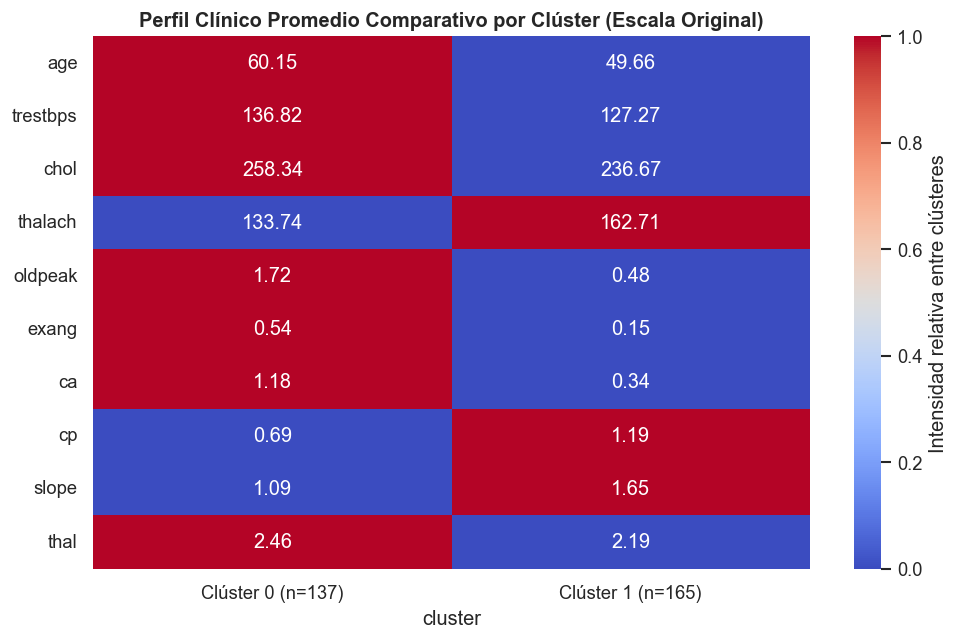

In [13]:
# Heatmap comparativo de perfiles por clúster
vars_clave = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'exang', 'ca', 'cp', 'slope', 'thal']
perfil_sub = perfil_orig[vars_clave]
perfil_norm = (perfil_sub - perfil_sub.min()) / (perfil_sub.max() - perfil_sub.min() + 1e-9)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(
    perfil_norm.T,
    annot=perfil_sub.T,
    fmt='.2f',
    cmap='coolwarm',
    cbar_kws={'label': 'Intensidad relativa entre clústeres'},
    ax=ax
)
ax.set_xticklabels([f'Clúster {c} (n={counts[c]})' for c in counts.index])
ax.set_title('Perfil Clínico Promedio Comparativo por Clúster (Escala Original)', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/perfil_clusters_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretación descriptiva de los grupos (sin etiquetas diagnósticas):**
- **Clúster 0 (`n = 137`, `45.4%`) — "Perfil de mayor carga de esfuerzo cardíaco aparente":** mayor edad promedio (`60.15` años), mayor presión arterial en reposo (`136.82` mm Hg) y colesterol (`258.34` mg/dl), menor frecuencia cardíaca máxima alcanzada (`133.74` lpm), mayor depresión del segmento ST (`oldpeak = 1.72`), mayor proporción de angina inducida por ejercicio (`0.54`) y mayor número de vasos coloreados por fluoroscopía (`1.18`).
- **Clúster 1 (`n = 165`, `54.6%`) — "Perfil de menor esfuerzo cardíaco aparente":** menor edad promedio (`49.66` años), menor presión arterial (`127.27` mm Hg), mayor frecuencia cardíaca máxima (`162.71` lpm), mínima depresión ST (`0.48`), baja proporción de angina inducida (`0.15`) y menor promedio de vasos coloreados (`0.34`).

## 7. Visualización Multidimensional: PCA y t-SNE

Varianza explicada por PCA: PC1=26.1%, PC2=13.4%, Total=39.5%


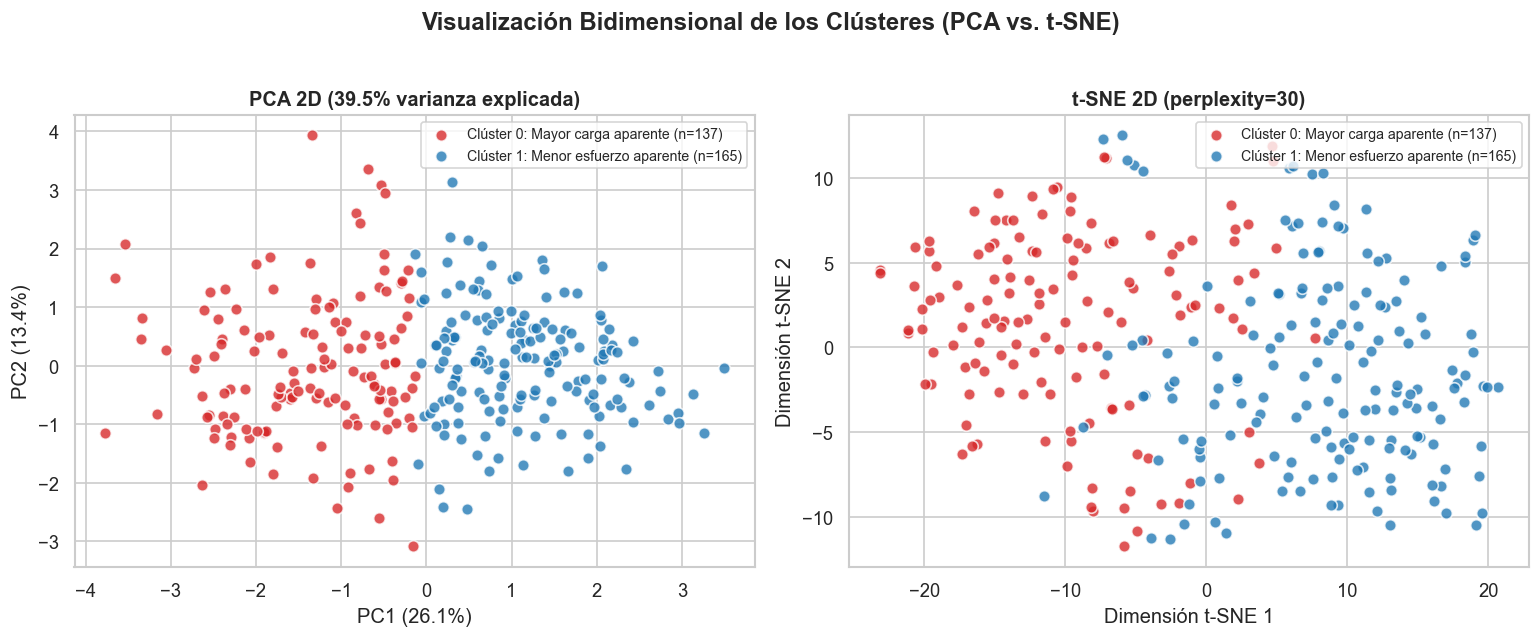

In [14]:
# Proyección PCA (2D) y t-SNE (2D) sobre el espacio preprocesado final
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_trans)
var_exp = pca_2d.explained_variance_ratio_

tsne_2d = TSNE(n_components=2, perplexity=30, learning_rate='auto', init='pca', random_state=42)
X_tsne = tsne_2d.fit_transform(X_trans)

print(f'Varianza explicada por PCA: PC1={var_exp[0]*100:.1f}%, PC2={var_exp[1]*100:.1f}%, Total={var_exp.sum()*100:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
palette = {0: '#d62728', 1: '#1f77b4'}
nombres = {
    0: 'Clúster 0: Mayor carga aparente (n=137)',
    1: 'Clúster 1: Menor esfuerzo aparente (n=165)'
}

for cid in [0, 1]:
    mask = (clusters == cid)
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=palette[cid], label=nombres[cid], alpha=0.78, edgecolors='white', s=48)
    axes[1].scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=palette[cid], label=nombres[cid], alpha=0.78, edgecolors='white', s=48)

axes[0].set_title(f'PCA 2D ({var_exp.sum()*100:.1f}% varianza explicada)', fontweight='bold')
axes[0].set_xlabel(f'PC1 ({var_exp[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({var_exp[1]*100:.1f}%)')
axes[0].legend(fontsize=8.5)

axes[1].set_title('t-SNE 2D (perplexity=30)', fontweight='bold')
axes[1].set_xlabel('Dimensión t-SNE 1')
axes[1].set_ylabel('Dimensión t-SNE 2')
axes[1].legend(fontsize=8.5)

plt.suptitle('Visualización Bidimensional de los Clústeres (PCA vs. t-SNE)', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/pca_tsne_clusters.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Comparación con Alternativa ($k=3$) y Contraste Exploratorio con `target`

In [15]:
# Contraste con k=3 sobre el mismo espacio preprocesado
km_k3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_trans)
print(f'Silueta k=2: {sil_final:.4f} | Silueta k=3: {silhouette_score(X_trans, km_k3.labels_):.4f}')
print('Tamaños k=3:', pd.Series(km_k3.labels_).value_counts().sort_index().to_dict())

# Contraste estrictamente descriptivo con target (NO valida el modelo como clasificador)
cruce_target = pd.crosstab(df_res['cluster'], df_res['target'], margins=True)
cruce_target.index = ['Clúster 0 (Mayor carga)', 'Clúster 1 (Menor esfuerzo)', 'Total']
cruce_target.columns = ['target = 0', 'target = 1', 'Total']
print()
print('Cruce descriptivo entre clústeres y variable de referencia diagnóstica (solo exploratorio):')
cruce_target

Silueta k=2: 0.1722 | Silueta k=3: 0.1180
Tamaños k=3: {0: 97, 1: 106, 2: 99}

Cruce descriptivo entre clústeres y variable de referencia diagnóstica (solo exploratorio):


,target = 0,target = 1,Total
Clúster 0 (Mayor carga),102,35,137
Clúster 1 (Menor esfuerzo),36,129,165
Total,138,164,302


## 9. Serialización del Pipeline y Casos de Prueba de Consistencia para Streamlit

In [16]:
# Guardar exactamente el mismo Pipeline y PCA evaluados aquí
joblib.dump(pipeline_final, 'models/clustering_pipeline.joblib')
joblib.dump(pca_2d, 'models/pca_2d.joblib')

# Casos de prueba exactos para verificar consistencia Notebook <-> Streamlit
# Incluyen casos representativos, valores límite y registros reales conocidos de heart.csv
row_0 = df_clean.iloc[0]
row_165 = df_clean.iloc[165]

casos_prueba = [
    {
        'caso': 'Prueba 1 - Caso normal (Perfil mayor carga)',
        'origen': 'Caso sintético representativo de carga cardiovascular elevada',
        'age': 63, 'trestbps': 145, 'chol': 260, 'thalach': 125, 'oldpeak': 2.4, 'ca': 2,
        'sex': 1, 'fbs': 1, 'exang': 1, 'cp': 0, 'restecg': 0, 'slope': 1, 'thal': 3
    },
    {
        'caso': 'Prueba 2 - Caso normal (Perfil menor esfuerzo)',
        'origen': 'Caso sintético representativo de menor esfuerzo aparente',
        'age': 44, 'trestbps': 120, 'chol': 210, 'thalach': 172, 'oldpeak': 0.0, 'ca': 0,
        'sex': 0, 'fbs': 0, 'exang': 0, 'cp': 2, 'restecg': 1, 'slope': 2, 'thal': 2
    },
    {
        'caso': 'Prueba 3 - Registro conocido del dataset (Paciente #0 de heart.csv)',
        'origen': f"Registro real índice 0 de df_clean (target original = {int(row_0['target'])})",
        **{k: (float(row_0[k]) if k == 'oldpeak' else int(row_0[k])) for k in FEATURES}
    },
    {
        'caso': 'Prueba 4 - Registro conocido del dataset (Paciente #165 de heart.csv)',
        'origen': f"Registro real índice 165 de df_clean (target original = {int(row_165['target'])})",
        **{k: (float(row_165[k]) if k == 'oldpeak' else int(row_165[k])) for k in FEATURES}
    },
    {
        'caso': 'Prueba 5 - Valores límite observados del rango clínico',
        'origen': 'Combinación extrema en los límites observados del conjunto de datos',
        'age': 77, 'trestbps': 200, 'chol': 564, 'thalach': 71, 'oldpeak': 6.2, 'ca': 4,
        'sex': 1, 'fbs': 1, 'exang': 1, 'cp': 0, 'restecg': 2, 'slope': 0, 'thal': 3
    }
]

pipe_cargado = joblib.load('models/clustering_pipeline.joblib')
verified_cases = []
for cp_item in casos_prueba:
    row_df = pd.DataFrame([{k: cp_item[k] for k in FEATURES}])
    pred = int(pipe_cargado.predict(row_df)[0])
    dists = pipe_cargado.transform(row_df)[0]
    verified_cases.append({
        'caso': cp_item['caso'],
        'origen': cp_item['origen'],
        'inputs': {k: cp_item[k] for k in FEATURES},
        'cluster': pred,
        'dist_c0': round(float(dists[0]), 4),
        'dist_c1': round(float(dists[1]), 4),
    })
    print(f"{cp_item['caso']} -> Clúster asignado: {pred} | Distancias: c0={dists[0]:.3f}, c1={dists[1]:.3f}")

# Metadatos verificables para la interfaz Streamlit (fuente única de verdad)
metadata = {
    'features': FEATURES,
    'num_cols': NUM_COLS,
    'bin_cols': BIN_COLS,
    'nom_cols': NOM_COLS,
    'n_records_raw': int(len(df)),
    'n_duplicates_removed': duplicados,
    'n_records': int(len(df_res)),
    'n_transformed_features': int(X_trans.shape[1]),
    'metrics': {
        'inertia': round(float(inercia_final), 2),
        'silhouette': round(float(sil_final), 4),
        'davies_bouldin': round(float(db_final), 4),
        'calinski_harabasz': round(float(ch_final), 2),
        'pca_variance_ratio': [round(float(v), 4) for v in var_exp]
    },
    'comparison_approaches': comp_df.to_dict(orient='records'),
    'metrics_by_k': df_k.to_dict(orient='records'),
    'target_crosstab': {
        'cluster_0': {'target_0': int(cruce_target.iloc[0, 0]), 'target_1': int(cruce_target.iloc[0, 1]), 'total': int(cruce_target.iloc[0, 2])},
        'cluster_1': {'target_0': int(cruce_target.iloc[1, 0]), 'target_1': int(cruce_target.iloc[1, 1]), 'total': int(cruce_target.iloc[1, 2])},
    },
    'cluster_sizes': {str(int(k)): int(v) for k, v in counts.items()},
    'cluster_labels': {
        '0': 'Perfil de mayor carga de esfuerzo cardíaco aparente',
        '1': 'Perfil de menor esfuerzo cardíaco aparente'
    },
    'cluster_profiles_mean': perfil_orig.to_dict(orient='index'),
    'feature_ranges': {
        col: {'min': float(X[col].min()), 'max': float(X[col].max()), 'median': float(X[col].median())}
        for col in FEATURES
    },
    'verified_test_cases': verified_cases
}

with open('models/cluster_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

Prueba 1 - Caso normal (Perfil mayor carga) -> Clúster asignado: 0 | Distancias: c0=1.823, c1=4.098
Prueba 2 - Caso normal (Perfil menor esfuerzo) -> Clúster asignado: 1 | Distancias: c0=4.007, c1=1.706
Prueba 3 - Registro conocido del dataset (Paciente #0 de heart.csv) -> Clúster asignado: 0 | Distancias: c0=2.819, c1=3.451
Prueba 4 - Registro conocido del dataset (Paciente #165 de heart.csv) -> Clúster asignado: 0 | Distancias: c0=2.074, c1=4.071
Prueba 5 - Valores límite observados del rango clínico -> Clúster asignado: 0 | Distancias: c0=9.277, c1=11.249


## 10. Conclusiones Finales

1. **Integración del pipeline:** El reemplazo de la codificación ordinal del segundo avance por un `ColumnTransformer` (`StandardScaler` para variables numéricas, `passthrough` para binarias y `OneHotEncoder` para variables nominales) mejoró todas las métricas internas de K-means con $k=2$: silueta de `0.1681` a `0.1722`, índice Davies-Bouldin de `2.1900` a `2.0650` e índice Calinski-Harabasz de `54.99` a `66.61`.
2. **Interpretación crítica de la métrica (< 0.70):** La comparación con `RobustScaler`, agrupamiento jerárquico (Ward) y modelos de mezcla gaussiana (GMM) confirmó que el coeficiente de silueta moderado-bajo es propio de la superposición fisiológica del conjunto de datos clínicos mixtos, y no un error de implementación.
3. **Perfiles diferenciados y reproducibilidad:** Los dos grupos obtenidos (`n=137` y `n=165` sobre los `302` registros únicos) muestran diferencias claras en edad, frecuencia cardíaca máxima, depresión del segmento ST, angina inducida y vasos coloreados por fluoroscopía. El `Pipeline` serializado en `models/clustering_pipeline.joblib` garantiza la misma transformación y asignación tanto en el notebook como en la aplicación web en Streamlit.